In [6]:
# Setup: config + imports
import glob
import os
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator

# Config
CROP_OUT_DIR = "../../Data/AIRS-cropped-greater-domain"
VARNAME      = "co_mmr_midtrop"
MW_RATIO     = 28.01 / 44.01          # CO / CO2 molar-mass conversion
OUT_DIR      = "../../Figures/greater-domain"
os.makedirs(OUT_DIR, exist_ok=True)

# Balanced window: 23 whole years
START_TS = pd.Timestamp("2019-01-01")
END_TS   = pd.Timestamp("2025-12-01")

## Interpolation to fill gaps in the data (2 months)

In [7]:
# Build gap-free monthly maps over the window, then the spatial-mean series.
crop_files = sorted(glob.glob(os.path.join(CROP_OUT_DIR, "*.nc")))
print(f"Found {len(crop_files)} cropped files")

# Load each month's (lat, lon) map: mean over orbit passes, ratio-corrected.
obs_maps = {}
lons = lats = None
for f in crop_files:
    stem = os.path.splitext(os.path.basename(f))[0]
    date = pd.Timestamp(f"{stem[:4]}-{stem[4:]}-01")
    if not (START_TS <= date <= END_TS):
        continue
    ds_g = xr.open_dataset(f, decode_timedelta=False)
    if lons is None:
        lons = ds_g["lon"].values
        lats = ds_g["lat"].values
    obs_maps[date] = ds_g[VARNAME].mean(dim="orbit_pass", skipna=True).values * MW_RATIO
    ds_g.close()

n_lat, n_lon = len(lats), len(lons)

# Full monthly calendar over the window.
months = pd.date_range(START_TS, END_TS, freq="MS")

# Stack into a (time, lat, lon) cube; missing months stay all-NaN.
raw_maps = np.full((len(months), n_lat, n_lon), np.nan)
has_obs = np.zeros(len(months), dtype=bool)
for i, d in enumerate(months):
    if d in obs_maps:
        raw_maps[i] = obs_maps[d]
        has_obs[i] = True
is_interp = ~has_obs

# Interpolate maps in time, per pixel, to fill missing months.
final_maps = xr.DataArray(
    raw_maps, dims=("time", "lat", "lon"),
    coords={"time": months, "lat": lats, "lon": lons},
)
final_maps = (final_maps.interpolate_na(dim="time", method="linear")
                        .bfill("time").ffill("time"))

# Time series = spatial mean of each map.
ts_dates = months
ts_co    = final_maps.mean(dim=("lat", "lon"), skipna=True).values

# Diagnostics.
n_pix = n_lat * n_lon
filled_dates = [d.strftime('%Y-%m') for d in months[is_interp]]
print(f"Calendar months   : {len(months)}   ({START_TS:%b %Y} - {END_TS:%b %Y})")
print(f"Observed maps      : {has_obs.sum()}")
print(f"Reconstructed maps : {is_interp.sum()}  -> {filled_dates}")
print(f"Grid per map       : {n_lat} lat x {n_lon} lon = {n_pix} pixels")
for i in np.where(is_interp)[0]:
    n_valid_orig = int(np.isfinite(raw_maps[i]).sum())
    n_valid_new  = int(np.isfinite(final_maps.values[i]).sum())
    print(f"   {months[i].strftime('%Y-%m')}: filled {n_valid_new - n_valid_orig} "
          f"pixels  ->  map mean = {ts_co[i]:.4e} kg/kg")

n_dead = int(np.isnan(final_maps.values).all(axis=0).sum())
print(f"Pixels never observed (left NaN): {n_dead}")
print(f"Date range : {ts_dates[0].date()}  ->  {ts_dates[-1].date()}")
print(f"CO range   : {np.nanmin(ts_co):.4e} - {np.nanmax(ts_co):.4e}  kg/kg")

Found 279 cropped files
Calendar months   : 84   (Jan 2019 - Dec 2025)
Observed maps      : 82
Reconstructed maps : 2  -> ['2023-09', '2025-12']
Grid per map       : 69 lat x 124 lon = 8556 pixels
   2023-09: filled 8556 pixels  ->  map mean = 9.0617e-08 kg/kg
   2025-12: filled 8556 pixels  ->  map mean = 7.9476e-08 kg/kg
Pixels never observed (left NaN): 0
Date range : 2019-01-01  ->  2025-12-01
CO range   : 7.9113e-08 - 1.0226e-07  kg/kg


## Mean and SD maps

Stack shape : (84, 69, 124)   (2019-01 - 2025-12)
Mean range  : 7.6622e-08 - 9.7038e-08  kg/kg
Std  range  : 3.3153e-09 - 1.4329e-08  kg/kg


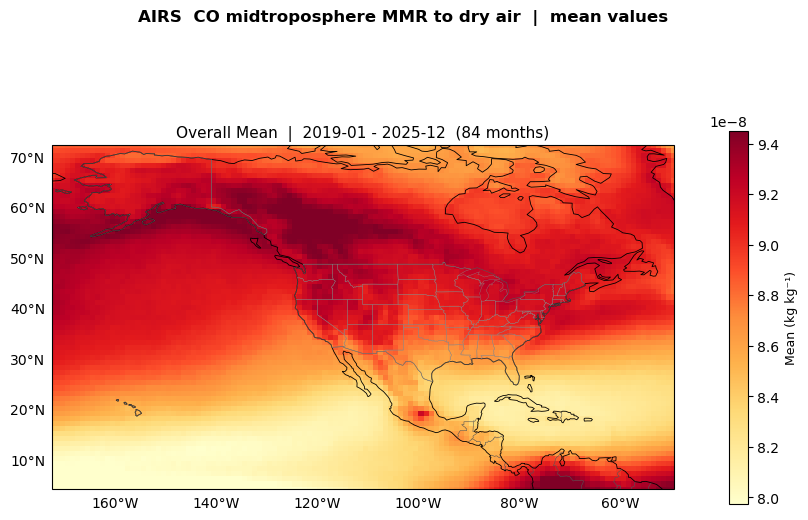

Saved -> ../../Figures/greater-domain\co_mmr_midtrop_mean_2003_2025.png


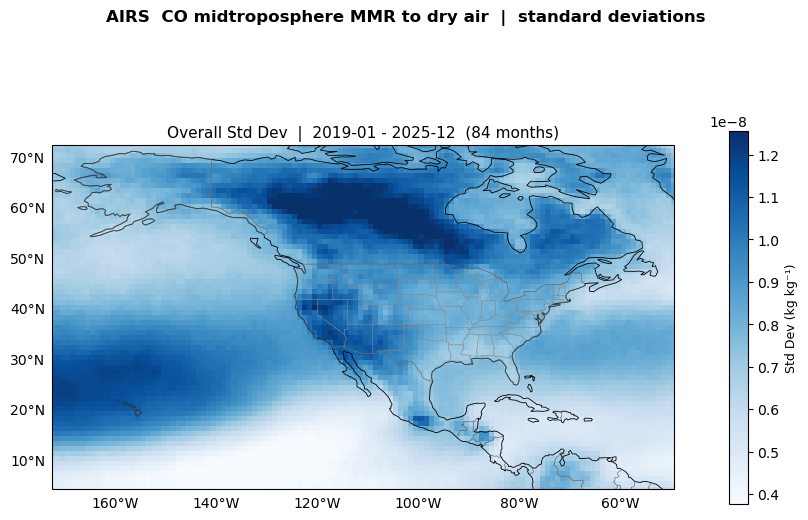

Saved -> ../../Figures/greater-domain\co_mmr_midtrop_std_2003_2025.png


In [8]:
# Pixel-wise mean & std across all months of the gap-free cube.
import cartopy.crs as ccrs
import cartopy.feature as cfeature

FIG_DIR = OUT_DIR
os.makedirs(FIG_DIR, exist_ok=True)

stack   = final_maps.values
co_mean = np.nanmean(stack, axis=0)
co_std  = np.nanstd (stack, axis=0, ddof=1)

n_months    = stack.shape[0]
label_first = months[0].strftime("%Y-%m")
label_last  = months[-1].strftime("%Y-%m")

print(f"Stack shape : {stack.shape}   ({label_first} - {label_last})")
print(f"Mean range  : {np.nanmin(co_mean):.4e} - {np.nanmax(co_mean):.4e}  kg/kg")
print(f"Std  range  : {np.nanmin(co_std ):.4e} - {np.nanmax(co_std ):.4e}  kg/kg")

# Map extent from data coords.
lon_min, lon_max = float(lons.min()), float(lons.max())
lat_min, lat_max = float(lats.min()), float(lats.max())


def draw_map(fig, ax, data, cmap, label, title):
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")

    pcm = ax.pcolormesh(
        lons, lats, data,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        vmin=np.nanpercentile(data, 2), vmax=np.nanpercentile(data, 98),
        shading="nearest",
    )
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False

    cb = fig.colorbar(pcm, ax=ax, orientation="vertical", fraction=0.03, pad=0.06)
    cb.set_label(label, fontsize=9)
    ax.set_title(title, fontsize=11, pad=6)


# Mean map.
fig_mean, ax_mean = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_mean, ax_mean, co_mean, plt.cm.YlOrRd,
         "Mean (kg kg⁻¹)",
         f"Overall Mean  |  {label_first} - {label_last}  ({n_months} months)")
fig_mean.suptitle(
    "AIRS  CO midtroposphere MMR to dry air  |  mean values ",
    fontsize=12, fontweight="bold",
)
out_mean = os.path.join(FIG_DIR, "co_mmr_midtrop_mean_2003_2025.png")
fig_mean.savefig(out_mean, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_mean)

# Std-dev map.
fig_std, ax_std = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_std, ax_std, co_std, plt.cm.Blues,
         "Std Dev (kg kg⁻¹)",
         f"Overall Std Dev  |  {label_first} - {label_last}  ({n_months} months)")
fig_std.suptitle(
    "AIRS  CO midtroposphere MMR to dry air  |  standard deviations",
    fontsize=12, fontweight="bold",
)
out_std = os.path.join(FIG_DIR, "co_mmr_midtrop_std_2003_2025.png")
fig_std.savefig(out_std, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_std)

## Per-pixel linear fit using ordinary least squares 

In [9]:
# per-pixel linear fit in time
yr = np.arange(len(months)) / 12.0     #decimal years 

Y    = final_maps.values
yr_c = yr - yr.mean()
pixel_slope     = np.tensordot(yr_c, Y - Y.mean(axis=0, keepdims=True),
                               axes=(0, 0)) / np.sum(yr_c**2)   # (lat, lon) kg/kg/yr
pixel_intercept = Y.mean(axis=0) - pixel_slope * yr.mean()      # (lat, lon)

dead = np.all(np.isnan(Y), axis=0)
pixel_slope[dead]     = np.nan
pixel_intercept[dead] = np.nan

# Fitted trend line and residual (detrended) fields.
trend_field = xr.DataArray(
    pixel_intercept[None] + pixel_slope[None] * yr[:, None, None],
    dims=("time", "lat", "lon"), coords=final_maps.coords,
)
detr_field = (final_maps - trend_field).transpose("time", "lat", "lon")

print(f"Per-pixel fit : slope {np.nanmin(pixel_slope):.3e} - {np.nanmax(pixel_slope):.3e} kg/kg/yr")

Per-pixel fit : slope -1.287e-09 - 9.678e-10 kg/kg/yr


## Plot of slopes at each grid point

Per-pixel slope grid : (69, 124)  (lat x lon)
Slope range          : -1.287e-09 - 9.678e-10  kg/kg/yr
Domain-mean slope    : -2.596e-10  kg/kg/yr


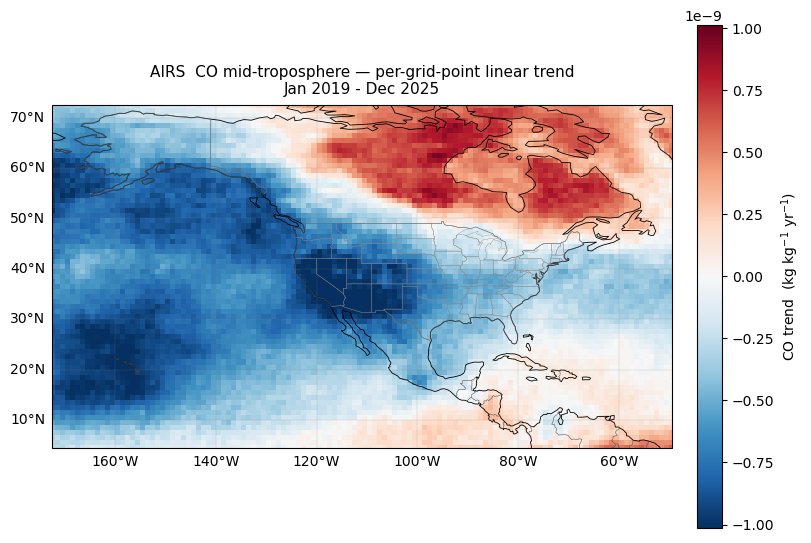

Saved -> ../../Figures/greater-domain\spatial_co_trend_slope_2003_2025.png


In [10]:
# Per-pixel slope map from the single fit.
import cartopy.crs as ccrs
import cartopy.feature as cfeature

slope = pixel_slope

print(f"Per-pixel slope grid : {slope.shape}  (lat x lon)")
print(f"Slope range          : {np.nanmin(slope):.3e} - {np.nanmax(slope):.3e}  kg/kg/yr")
print(f"Domain-mean slope    : {np.nanmean(slope):.3e}  kg/kg/yr")

# Plot.
ext = [float(lons.min()), float(lons.max()),
       float(lats.min()), float(lats.max())]

vmax_s = np.nanpercentile(np.abs(slope), 98)

fig_s, ax_s = plt.subplots(
    figsize=(8, 6),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
ax_s.set_extent(ext, crs=ccrs.PlateCarree())
ax_s.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
ax_s.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
ax_s.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")

pcm = ax_s.pcolormesh(
    lons, lats, slope,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", vmin=-vmax_s, vmax=vmax_s, shading="auto",
)
cb = fig_s.colorbar(pcm, ax=ax_s, orientation="vertical", shrink=0.85, pad=0.02)
cb.set_label("CO trend  (kg kg$^{-1}$ yr$^{-1}$)", fontsize=10)

gl = ax_s.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)
gl.top_labels = gl.right_labels = False

ax_s.set_title(
    "AIRS  CO mid-troposphere — per-grid-point linear trend\n"
    f"{months[0].strftime('%b %Y')} - {months[-1].strftime('%b %Y')}",
    fontsize=11, pad=8,
)

out_s = os.path.join(OUT_DIR, "spatial_co_trend_slope_2003_2025.png")
fig_s.savefig(out_s, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_s)

Ascending (13:30, day)     : mean 8.8698e-08  range 7.8988e-08 - 1.0375e-07 kg/kg
Descending (01:30, night)  : mean 8.7769e-08  range 7.8675e-08 - 1.0077e-07 kg/kg
Ascending - descending      : mean 9.2809e-10  (min -9.5094e-10, max 4.4104e-09) kg/kg


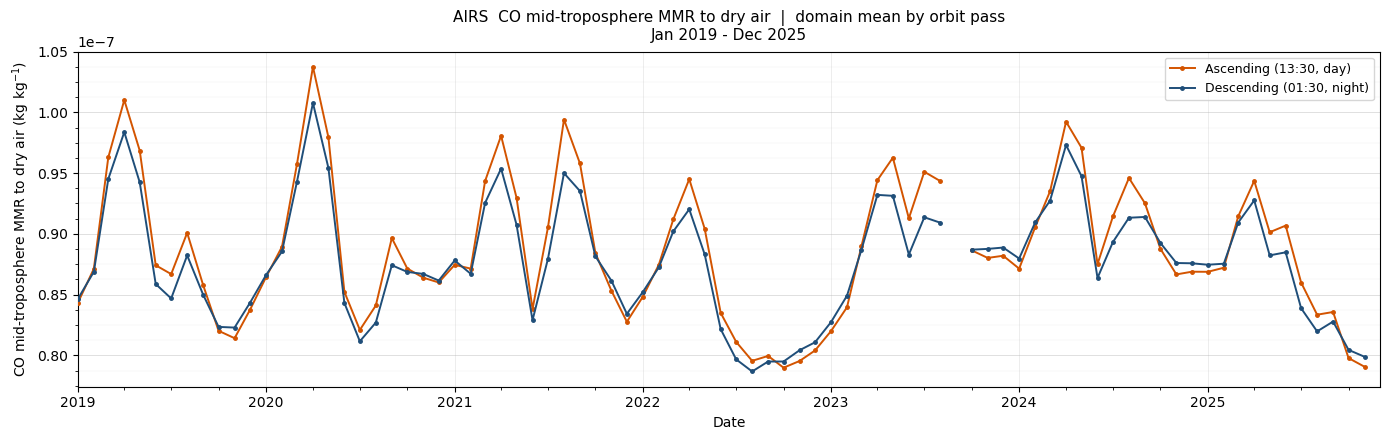

Saved -> ../../Figures/greater-domain\timeseries_co_asc_desc_2019_2025.png


In [11]:
# Domain-average co_mmr_midtrop time series, ascending vs descending orbit.
# orbit_pass = equatorial crossing time (h): 13.5 -> ascending (day), 1.5 -> descending (night).
ORBIT_LABELS = {13.5: "Ascending (13:30, day)", 1.5: "Descending (01:30, night)"}
ORBIT_COLORS = {13.5: "#d35400", 1.5: "#1f4e79"}

# Monthly domain means per orbit pass (ratio-corrected); missing months stay NaN.
orbit_ts = {op: np.full(len(months), np.nan) for op in ORBIT_LABELS}
for f in crop_files:
    stem = os.path.splitext(os.path.basename(f))[0]
    date = pd.Timestamp(f"{stem[:4]}-{stem[4:]}-01")
    if not (START_TS <= date <= END_TS):
        continue
    i = months.get_loc(date)
    with xr.open_dataset(f, decode_timedelta=False) as ds_o:
        dom_mean = (ds_o[VARNAME] * MW_RATIO).mean(dim=("lat", "lon"), skipna=True)
        for op in ORBIT_LABELS:
            orbit_ts[op][i] = float(dom_mean.sel(orbit_pass=op))

for op, lab in ORBIT_LABELS.items():
    print(f"{lab:27s}: mean {np.nanmean(orbit_ts[op]):.4e}  "
          f"range {np.nanmin(orbit_ts[op]):.4e} - {np.nanmax(orbit_ts[op]):.4e} kg/kg")
diff = orbit_ts[13.5] - orbit_ts[1.5]
print(f"Ascending - descending      : mean {np.nanmean(diff):.4e}  "
      f"(min {np.nanmin(diff):.4e}, max {np.nanmax(diff):.4e}) kg/kg")

# Plot.
fig_o, ax_o = plt.subplots(figsize=(14, 4.5))
for op, lab in ORBIT_LABELS.items():
    ax_o.plot(months, orbit_ts[op], lw=1.4, marker="o", ms=2.5,
              color=ORBIT_COLORS[op], label=lab, zorder=3)

ax_o.legend(fontsize=9, loc="upper right")
ax_o.set_title(
    "AIRS  CO mid-troposphere MMR to dry air  |  domain mean by orbit pass\n"
    f"{months[0].strftime('%b %Y')} - {months[-1].strftime('%b %Y')}",
    fontsize=11, pad=8,
)
ax_o.set_ylabel("CO mid-troposphere MMR to dry air (kg kg$^{-1}$)", fontsize=10)
ax_o.set_xlabel("Date", fontsize=10)

ax_o.xaxis.set_major_locator(mdates.YearLocator())
ax_o.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax_o.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax_o.yaxis.set_minor_locator(AutoMinorLocator(4))
ax_o.grid(axis="y", which="major", lw=0.5, alpha=0.55)
ax_o.grid(axis="y", which="minor", lw=0.2, alpha=0.3)
ax_o.grid(axis="x", which="major", lw=0.4, alpha=0.4)
ax_o.set_xlim(months[0], months[-1])

fig_o.tight_layout()
out_o = os.path.join(OUT_DIR, "timeseries_co_asc_desc_2019_2025.png")
fig_o.savefig(out_o, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_o)